# Road Crack & Pothole Detection Using YOLO + Deep Learning

## Google Colab Notebook — Pascal VOC XML to YOLO TXT

**Your dataset format:**

```text
Your_Dataset_Folder/
├── image_001.jpg
├── image_001.xml
├── image_002.jpg
├── image_002.xml
└── ...
```

The images and XML files can be in the **same folder**.

This notebook automatically:

- reads your Pascal VOC XML annotations
- converts XML bounding boxes to YOLO `.txt` labels
- treats `pothole` and `potholes` as the same class
- supports `crack`
- creates train/validation/test folders
- validates annotations
- visualizes bounding boxes
- trains a pretrained YOLO model
- evaluates Precision, Recall, mAP50 and mAP50-95
- tests images and videos
- exports the trained model

**You do NOT need to create the `.txt` files manually.**


## Cell 1 — Install Required Packages

Run this cell first.

In [1]:
!pip install -q ultralytics lxml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 7.1 MB/s eta 0:00:00


## Cell 2 — Import Libraries

In [2]:
import os
import random
import shutil
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch

from ultralytics import YOLO

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not available.")
    print("For Colab: Runtime -> Change runtime type -> select GPU.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## Cell 3 — Mount Google Drive

Your original images and XML files can remain in Google Drive.

## Cell 4 — Set Your Dataset Folder

### Change ONLY `SOURCE_DIR`

Set this to the folder containing your images and XML files.

Example:

```python
SOURCE_DIR = "/content/drive/MyDrive/potholes batch 1"
```

Do not point this to an individual image or XML file.

In [15]:
# ============================================================
# MOUNT GOOGLE DRIVE
# ============================================================
from google.colab import drive
import os

drive.mount("/content/drive")


# ============================================================
# DATASET AND PROJECT PATHS
# ============================================================

SOURCE_DIR = "/content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/Potholes"

PROJECT_DIR = "/content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project"


# ============================================================
# CHECK PATHS
# ============================================================

print("Dataset folder:", SOURCE_DIR)
print("Output folder:", PROJECT_DIR)

print("\nDataset exists:", os.path.isdir(SOURCE_DIR))

if not os.path.isdir(SOURCE_DIR):
    raise FileNotFoundError(
        f"Dataset folder does not exist:\n{SOURCE_DIR}\n\n"
        "Please check the folder name in Google Drive."
    )

print("\n✅ Dataset folder found successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset folder: /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/Potholes
Output folder: /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project

Dataset exists: True

✅ Dataset folder found successfully!


## Cell 5 — Find Images and XML Files

This scans the folder and counts the images and XML annotation files.

In [16]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

source = Path(SOURCE_DIR)

image_files = sorted([
    p for p in source.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
])

xml_files = sorted([
    p for p in source.iterdir()
    if p.is_file() and p.suffix.lower() == ".xml"
])

print("Number of images:", len(image_files))
print("Number of XML files:", len(xml_files))

print("\nFirst 10 images:")
for p in image_files[:10]:
    print(" ", p.name)

print("\nFirst 10 XML files:")
for p in xml_files[:10]:
    print(" ", p.name)


Number of images: 209
Number of XML files: 195

First 10 images:
  20220815_16_11_41_045_000_jT85iRGUsKVY0iTx40U5DTQKCYf2_F_3264_2448 (1).jpg
  20220815_16_11_41_045_000_jT85iRGUsKVY0iTx40U5DTQKCYf2_F_3264_2448.jpg
  20220816_07_21_10_305_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120 (1).jpg
  20220816_07_21_10_305_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120.jpg
  20220816_07_21_33_130_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120 (1).jpg
  20220816_07_21_33_130_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120.jpg
  20220816_07_24_04_022_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120 (1).jpg
  20220816_07_24_04_022_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120.jpg
  20220816_07_24_19_705_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120 (1).jpg
  20220816_07_24_19_705_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120.jpg

First 10 XML files:
  20220815_16_11_41_045_000_jT85iRGUsKVY0iTx40U5DTQKCYf2_F_3264_2448 (1).xml
  20220815_16_11_41_045_000_jT85iRGUsKVY0iTx40U5DTQKCYf2_F_3264_2448.xml
  20220816_07_

## Cell 6 — Check Image/XML Matching

Normally:

```text
image001.jpg
image001.xml
```

must have the same filename stem.

In [17]:
image_stems = {p.stem for p in image_files}
xml_stems = {p.stem for p in xml_files}

missing_xml = sorted(image_stems - xml_stems)
missing_images = sorted(xml_stems - image_stems)

print("Images without XML:", len(missing_xml))
for name in missing_xml[:20]:
    print(" ", name)

print("\nXML files without image:", len(missing_images))
for name in missing_images[:20]:
    print(" ", name)

paired_images = [p for p in image_files if p.stem in xml_stems]

print("\nMatched image/XML pairs:", len(paired_images))


Images without XML: 14
  20220816_08_12_06_208_000_LLecjK953OYwp86bcQI2dNU3ZBt1_F_3264_2448
  20220816_13_46_37_816_000_bfSm2U74UHdSXd2DG14bHRvOhhI2_F_3000_4000
  20220816_13_46_37_816_000_bfSm2U74UHdSXd2DG14bHRvOhhI2_F_3000_4000 (1)
  20220816_22_31_07_444_000_8Ja7kUiyyyRLfXzpwECAE7mQmFH2_T_4160_3120
  20220817_08_10_40_891_000_TRIhBb1cEeebPUftMdWRoZiypzD2_F_4080_3072
  20220817_08_11_16_829_000_TRIhBb1cEeebPUftMdWRoZiypzD2_F_4080_3072
  20220817_08_11_41_463_000_TRIhBb1cEeebPUftMdWRoZiypzD2_F_4080_3072
  20220817_08_12_14_805_000_TRIhBb1cEeebPUftMdWRoZiypzD2_F_4080_3072
  20220817_08_13_29_181_000_TRIhBb1cEeebPUftMdWRoZiypzD2_F_4080_3072
  20220818_13_34_26_267_000_ouxWjmafoFhCAHIynI1zRmNmZYw1_F_3264_2448
  20220818_13_34_26_267_000_ouxWjmafoFhCAHIynI1zRmNmZYw1_F_3264_2448 (1)
  20220819_09_08_41_274_000_3Du7psGgitewpjIJfxWYyXPV8f73_F_3840_2880
  20220820_05_49_28_013_000_Y6UC7CIZwGVM8XNNggIseRruAWf2_F_3000_4000
  20220820_09_57_01_552_000_TlzcyiyDxeculCaV2ZSgHBjBcvd2_T_4160_3120

XM

## Cell 7 — Define Classes

Your example XML contains:

```xml
<name>potholes</name>
```

The notebook maps both `pothole` and `potholes` to class `1`.

Classes:

```text
0 = crack
1 = pothole
```

In [18]:
CLASS_MAPPING = {
    "crack": 0,
    "pothole": 1,
    "potholes": 1,
}

CLASS_NAMES = {
    0: "crack",
    1: "pothole",
}

print("Class mapping:")
for name, class_id in CLASS_MAPPING.items():
    print(f"  {name} -> {class_id}")


Class mapping:
  crack -> 0
  pothole -> 1
  potholes -> 1


## Cell 8 — Convert Pascal VOC XML to YOLO TXT

### This is the important conversion step.

Your XML contains pixel coordinates:

```text
xmin
ymin
xmax
ymax
```

YOLO requires:

```text
class_id x_center y_center width height
```

with coordinates normalized between 0 and 1.

For example, the XML you showed:

```text
xmin = 1273
ymin = 1071
xmax = 1531
ymax = 1239
```

is automatically converted to YOLO format.

The original XML files are not changed.

In [19]:
CONVERTED_LABEL_DIR = os.path.join(PROJECT_DIR, "all_labels")
os.makedirs(CONVERTED_LABEL_DIR, exist_ok=True)

def convert_voc_to_yolo(xml_path, txt_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    size = root.find("size")
    if size is None:
        raise ValueError("XML has no <size> section")

    width_node = size.find("width")
    height_node = size.find("height")

    if width_node is None or height_node is None:
        raise ValueError("XML is missing image width/height")

    img_w = float(width_node.text)
    img_h = float(height_node.text)

    if img_w <= 0 or img_h <= 0:
        raise ValueError("Invalid image dimensions")

    lines = []
    unknown_classes = []

    for obj in root.findall("object"):
        name_node = obj.find("name")
        box = obj.find("bndbox")

        if name_node is None or box is None:
            continue

        class_name = name_node.text.strip().lower()

        if class_name not in CLASS_MAPPING:
            unknown_classes.append(class_name)
            continue

        class_id = CLASS_MAPPING[class_name]

        xmin = float(box.find("xmin").text)
        ymin = float(box.find("ymin").text)
        xmax = float(box.find("xmax").text)
        ymax = float(box.find("ymax").text)

        # Clip coordinates to image boundaries
        xmin = max(0.0, min(xmin, img_w))
        xmax = max(0.0, min(xmax, img_w))
        ymin = max(0.0, min(ymin, img_h))
        ymax = max(0.0, min(ymax, img_h))

        if xmax <= xmin or ymax <= ymin:
            continue

        # Pascal VOC -> YOLO
        x_center = ((xmin + xmax) / 2.0) / img_w
        y_center = ((ymin + ymax) / 2.0) / img_h
        box_width = (xmax - xmin) / img_w
        box_height = (ymax - ymin) / img_h

        lines.append(
            f"{class_id} {x_center:.6f} {y_center:.6f} "
            f"{box_width:.6f} {box_height:.6f}"
        )

    with open(txt_path, "w", encoding="utf-8") as f:
        f.write("\n".join(lines))

    return len(lines), unknown_classes


conversion_rows = []
unknown_counter = Counter()

for xml_path in xml_files:
    txt_path = Path(CONVERTED_LABEL_DIR) / f"{xml_path.stem}.txt"

    try:
        count, unknown = convert_voc_to_yolo(xml_path, txt_path)

        for item in unknown:
            unknown_counter[item] += 1

        conversion_rows.append({
            "xml_file": xml_path.name,
            "objects": count,
            "status": "OK"
        })

    except Exception as e:
        conversion_rows.append({
            "xml_file": xml_path.name,
            "objects": 0,
            "status": f"ERROR: {e}"
        })

conversion_df = pd.DataFrame(conversion_rows)

print("XML files processed:", len(conversion_df))
print("Successful:", (conversion_df["status"] == "OK").sum())
print("Errors:", (conversion_df["status"] != "OK").sum())

if unknown_counter:
    print("\nUnknown class names found:")
    print(dict(unknown_counter))
    print("\nIf these are valid classes, add them to CLASS_MAPPING.")
else:
    print("\nNo unknown class names found.")

display(conversion_df.head(10))


XML files processed: 195
Successful: 195
Errors: 0

Unknown class names found:
{'w': 6}

If these are valid classes, add them to CLASS_MAPPING.


,xml_file,objects,status
0,20220815_16_11_41_045_000_jT85iRGUsKVY0iTx40U5...,2,OK
1,20220815_16_11_41_045_000_jT85iRGUsKVY0iTx40U5...,2,OK
2,20220816_07_21_10_305_000_hnEYwZk1I5RsPJ0KVT40...,2,OK
3,20220816_07_21_10_305_000_hnEYwZk1I5RsPJ0KVT40...,2,OK
4,20220816_07_21_33_130_000_hnEYwZk1I5RsPJ0KVT40...,1,OK
5,20220816_07_21_33_130_000_hnEYwZk1I5RsPJ0KVT40...,1,OK
6,20220816_07_24_04_022_000_hnEYwZk1I5RsPJ0KVT40...,1,OK
7,20220816_07_24_04_022_000_hnEYwZk1I5RsPJ0KVT40...,1,OK
8,20220816_07_24_19_705_000_hnEYwZk1I5RsPJ0KVT40...,1,OK
9,20220816_07_24_19_705_000_hnEYwZk1I5RsPJ0KVT40...,1,OK


## Cell 9 — View One Generated TXT Annotation

A YOLO label file contains one line per bounding box.

Example:

```text
1 0.572712 0.353860 0.105392 0.051471
```

The first number (`1`) means pothole.

In [20]:
txt_files = sorted(Path(CONVERTED_LABEL_DIR).glob("*.txt"))

print("Generated TXT files:", len(txt_files))

if len(txt_files) == 0:
    raise RuntimeError("No TXT labels were generated. Check SOURCE_DIR and XML files.")

sample_txt = txt_files[0]

print("\nFile:", sample_txt.name)
print("=" * 70)
print(sample_txt.read_text(encoding="utf-8")[:5000])


Generated TXT files: 195

File: 20220815_16_11_41_045_000_jT85iRGUsKVY0iTx40U5DTQKCYf2_F_3264_2448 (1).txt
1 0.572712 0.353860 0.105392 0.051471
1 0.472835 0.401501 0.069036 0.037071


## Cell 10 — Create YOLO Train/Validation/Test Folders

The original folder is not modified.

A new dataset is created as:

```text
road_defect_yolo_project/
└── yolo_dataset/
    ├── train/
    │   ├── images/
    │   └── labels/
    ├── valid/
    │   ├── images/
    │   └── labels/
    └── test/
        ├── images/
        └── labels/
```

The split is approximately:

- 80% training
- 10% validation
- 10% testing

In [21]:
YOLO_DATASET_DIR = os.path.join(PROJECT_DIR, "yolo_dataset")

for split in ["train", "valid", "test"]:
    os.makedirs(os.path.join(YOLO_DATASET_DIR, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(YOLO_DATASET_DIR, split, "labels"), exist_ok=True)

if len(paired_images) < 10:
    print("WARNING: Dataset has fewer than 10 paired images.")
    print("For a meaningful deep-learning project, more images are recommended.")

random.seed(42)
random.shuffle(paired_images)

n = len(paired_images)

if n < 3:
    raise ValueError("At least 3 matched image/XML pairs are required.")

train_n = max(1, int(0.80 * n))
valid_n = max(1, int(0.10 * n))

# Keep at least one image for test
if train_n + valid_n >= n:
    valid_n = 1
    train_n = n - 2

train_images = paired_images[:train_n]
valid_images = paired_images[train_n:train_n + valid_n]
test_images = paired_images[train_n + valid_n:]

print("Total:", n)
print("Train:", len(train_images))
print("Valid:", len(valid_images))
print("Test :", len(test_images))

def copy_image_and_label(image_path, split):
    label_path = Path(CONVERTED_LABEL_DIR) / f"{image_path.stem}.txt"

    if not label_path.exists():
        raise FileNotFoundError(f"Missing TXT label: {label_path}")

    shutil.copy2(
        image_path,
        Path(YOLO_DATASET_DIR) / split / "images" / image_path.name
    )

    shutil.copy2(
        label_path,
        Path(YOLO_DATASET_DIR) / split / "labels" / f"{image_path.stem}.txt"
    )

for split, items in [
    ("train", train_images),
    ("valid", valid_images),
    ("test", test_images)
]:
    for image_path in items:
        copy_image_and_label(image_path, split)

print("\nYOLO dataset created successfully.")


Total: 195
Train: 156
Valid: 19
Test : 20

YOLO dataset created successfully.


## Cell 11 — Create data.yaml

YOLO uses this file to know:

- where the training images are
- where the validation images are
- where the test images are
- what the class names are

In [22]:
DATA_YAML = os.path.join(PROJECT_DIR, "data.yaml")

yaml_text = f'''path: {YOLO_DATASET_DIR}
train: train/images
val: valid/images
test: test/images

names:
  0: crack
  1: pothole
'''

with open(DATA_YAML, "w", encoding="utf-8") as f:
    f.write(yaml_text)

print(yaml_text)


path: /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project/yolo_dataset
train: train/images
val: valid/images
test: test/images

names:
  0: crack
  1: pothole



## Cell 12 — Validate YOLO TXT Annotations

This checks that every label has:

```text
5 values
valid class ID
coordinates between 0 and 1
positive width and height
```

In [23]:
def validate_label(label_path):
    errors = []

    text = label_path.read_text(encoding="utf-8").strip()

    if not text:
        return errors

    for line_number, line in enumerate(text.splitlines(), start=1):
        parts = line.split()

        if len(parts) != 5:
            errors.append(f"Line {line_number}: expected 5 values")
            continue

        try:
            class_id = int(parts[0])
            x, y, w, h = map(float, parts[1:])
        except ValueError:
            errors.append(f"Line {line_number}: invalid numeric value")
            continue

        if class_id not in CLASS_NAMES:
            errors.append(f"Line {line_number}: invalid class ID {class_id}")

        for name, value in [
            ("x_center", x),
            ("y_center", y),
            ("width", w),
            ("height", h)
        ]:
            if value < 0 or value > 1:
                errors.append(
                    f"Line {line_number}: {name}={value} is outside 0-1"
                )

        if w <= 0 or h <= 0:
            errors.append(
                f"Line {line_number}: width and height must be > 0"
            )

    return errors


all_validation = []

for split in ["train", "valid", "test"]:
    label_dir = Path(YOLO_DATASET_DIR) / split / "labels"

    for label_path in label_dir.glob("*.txt"):
        errors = validate_label(label_path)
        all_validation.append((split, label_path.name, errors))

bad = [x for x in all_validation if x[2]]

print("Labels checked:", len(all_validation))
print("Labels with errors:", len(bad))

for split, filename, errors in bad[:20]:
    print("\n", split, filename)
    for error in errors:
        print("  ", error)

if not bad:
    print("All YOLO annotations passed validation.")


Labels checked: 195
Labels with errors: 0
All YOLO annotations passed validation.


## Cell 13 — Count Crack and Pothole Objects

In [24]:
counts = Counter()

for split in ["train", "valid", "test"]:
    label_dir = Path(YOLO_DATASET_DIR) / split / "labels"

    for label_path in label_dir.glob("*.txt"):
        for line in label_path.read_text(encoding="utf-8").strip().splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                counts[CLASS_NAMES[class_id]] += 1

print("Object counts:")
for class_id, class_name in CLASS_NAMES.items():
    print(f"  {class_name}: {counts[class_name]}")


Object counts:
  crack: 0
  pothole: 514


## Cell 14 — Visualize Ground-Truth Bounding Boxes

Run this before training.

If the boxes correctly surround the potholes/cracks in your images, the XML-to-YOLO conversion is working correctly.

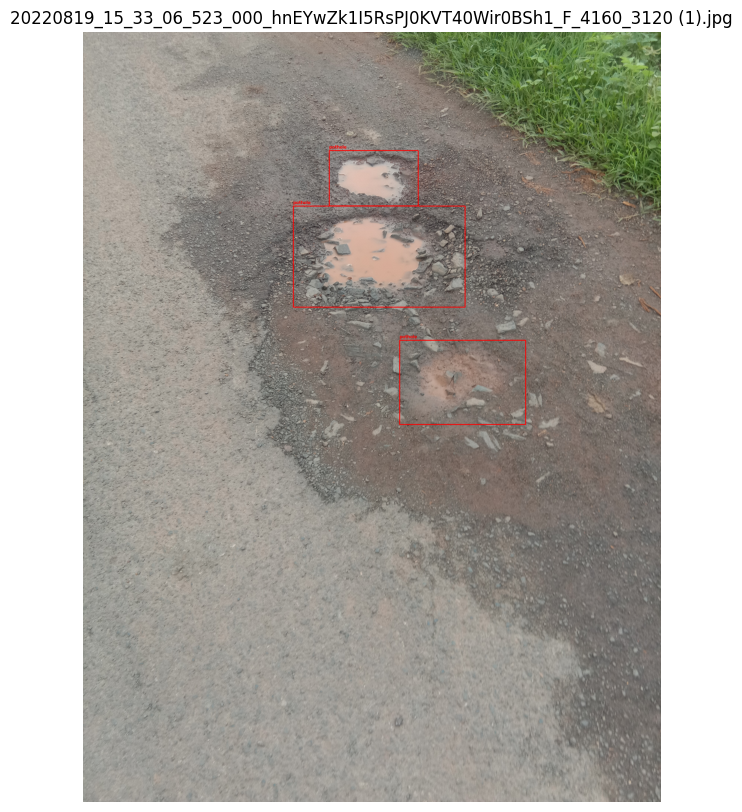

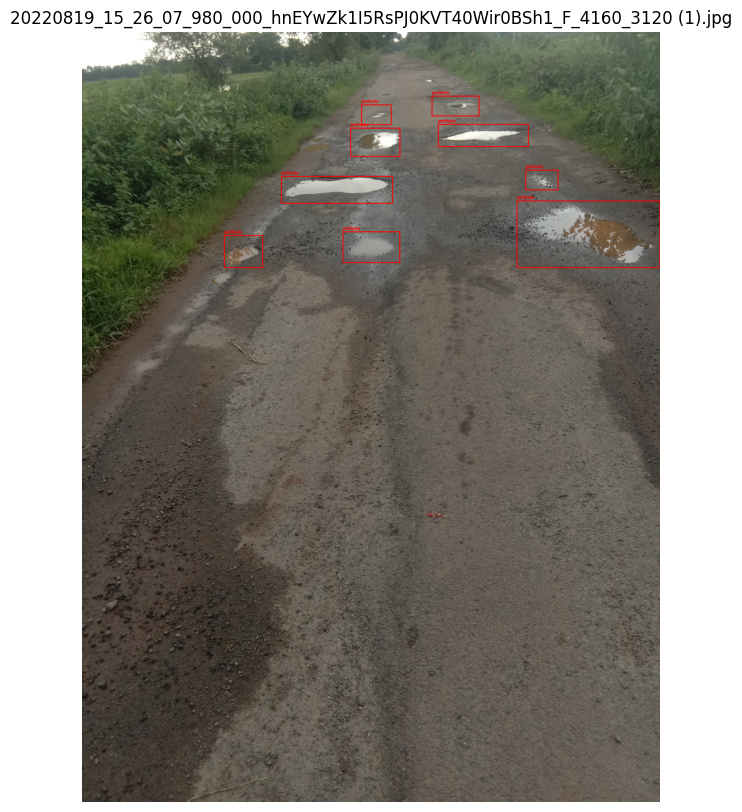

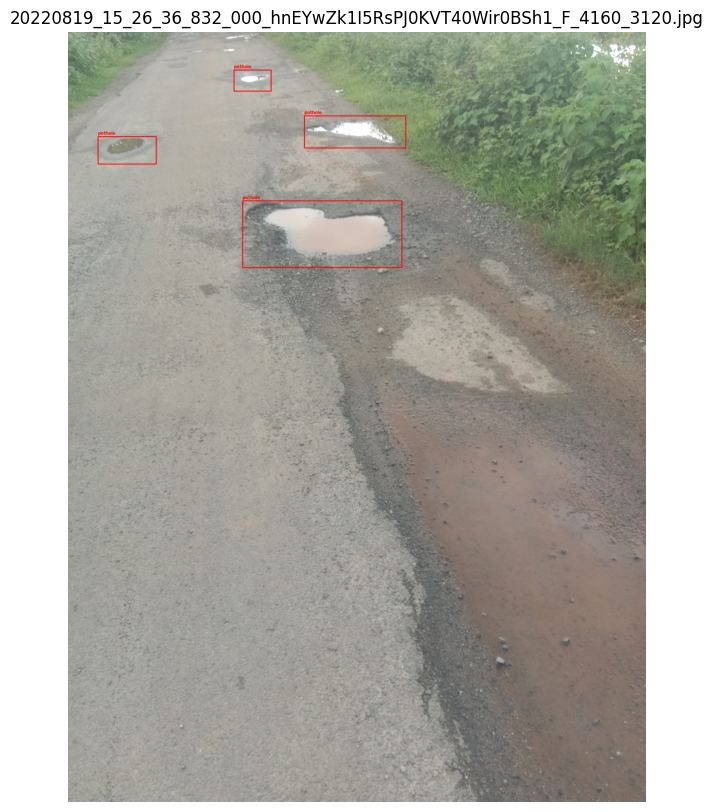

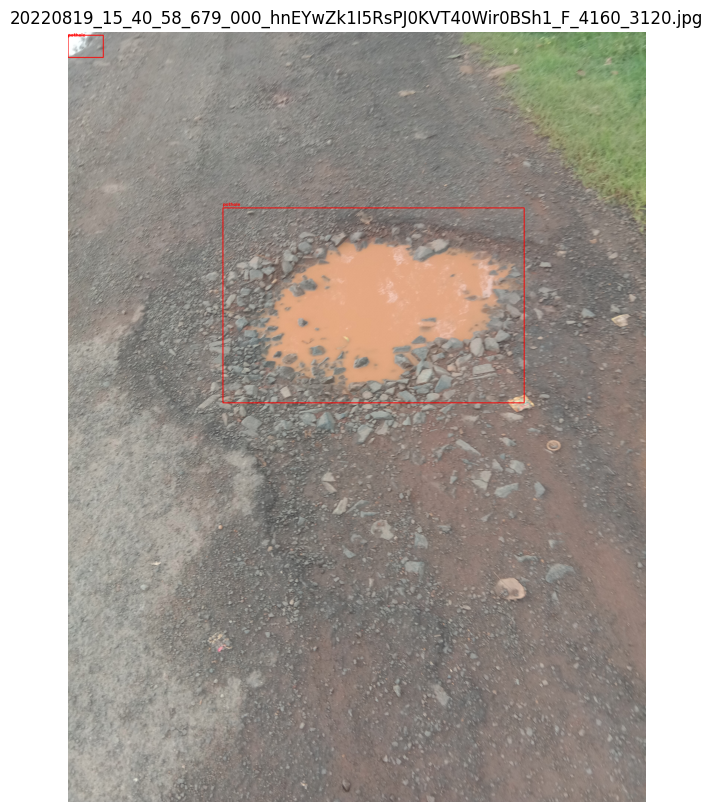

In [25]:
def visualize_yolo_annotation(image_path, label_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    label_text = label_path.read_text(encoding="utf-8").strip()

    for line in label_text.splitlines():
        if not line.strip():
            continue

        class_id, xc, yc, bw, bh = map(float, line.split())
        class_id = int(class_id)

        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        x1 = max(0, min(x1, w - 1))
        y1 = max(0, min(y1, h - 1))
        x2 = max(0, min(x2, w - 1))
        y2 = max(0, min(y2, h - 1))

        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 4)
        cv2.putText(
            image,
            CLASS_NAMES[class_id],
            (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.9,
            (255, 0, 0),
            3
        )

    return image


train_image_dir = Path(YOLO_DATASET_DIR) / "train" / "images"
train_label_dir = Path(YOLO_DATASET_DIR) / "train" / "labels"

available = list(train_image_dir.glob("*"))

for image_path in random.sample(available, min(4, len(available))):
    label_path = train_label_dir / f"{image_path.stem}.txt"

    image = visualize_yolo_annotation(image_path, label_path)

    plt.figure(figsize=(8, 10))
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()


## Cell 15 — Load Pretrained YOLO Model

This uses transfer learning.

Start with `yolo11s.pt`.

If your Colab GPU runs out of memory, change it to:

```python
MODEL_NAME = "yolo11n.pt"
```

In [56]:
MODEL_NAME = "yolo26s"

model = YOLO(MODEL_NAME)

print("Model loaded:", MODEL_NAME)


Model loaded: yolo26s


## Cell 16 — Train YOLO

### Recommended first training run

- Epochs: 50
- Image size: 640
- Batch size: 16
- Early stopping patience: 10

If GPU memory is insufficient, reduce `BATCH_SIZE` to 8 or 4.

In [57]:
EPOCHS = 50
IMG_SIZE = 640
BATCH_SIZE = 16

DEVICE = 0 if torch.cuda.is_available() else "cpu"

RUNS_DIR = "/content/drive/MyDrive/AI_Projects/road_df_run"

train_results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    patience=10,
    project=RUNS_DIR,
    name="yolo11_road_defect",
    exist_ok=True,
    pretrained=True,
    optimizer="auto",
    verbose=True
)

print("Training finished.")


Ultralytics 8.4.142 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, mul

## Cell 17 — Load `best.pt`

YOLO saves the best model during training.

This is the model we use for evaluation and testing.

In [58]:
BEST_MODEL = os.path.join(
    RUNS_DIR,
    "yolo11_road_defect",
    "weights",
    "best.pt"
)

if not os.path.exists(BEST_MODEL):
    raise FileNotFoundError(
        f"best.pt was not found at:\n{BEST_MODEL}"
    )

best_model = YOLO(BEST_MODEL)

print("Best model:", BEST_MODEL)


Best model: /content/drive/MyDrive/AI_Projects/road_df_run/yolo11_road_defect/weights/best.pt


## Cell 18 — Show Training Results

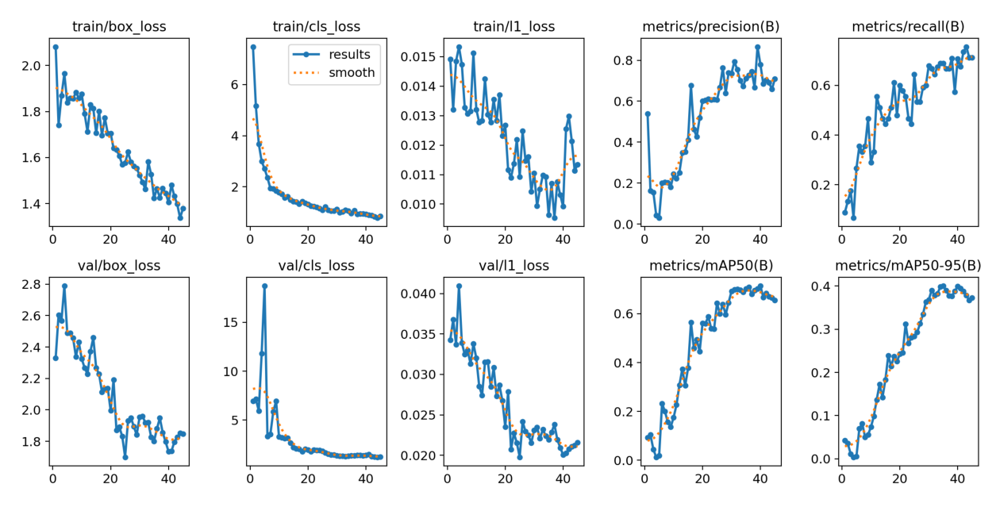

In [59]:
results_png = os.path.join(
    RUNS_DIR,
    "yolo11_road_defect",
    "results.png"
)

if os.path.exists(results_png):
    image = plt.imread(results_png)
    plt.figure(figsize=(16, 10))
    plt.imshow(image)
    plt.axis("off")
    plt.show()
else:
    print("results.png not found.")


## Cell 19 — Evaluate Precision, Recall, mAP50 and mAP50-95

In [60]:
metrics = best_model.val(
    data=DATA_YAML,
    split="val",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True
)

print("===== OVERALL VALIDATION METRICS =====")
print(f"Precision : {metrics.box.mp:.4f}")
print(f"Recall    : {metrics.box.mr:.4f}")
print(f"mAP50     : {metrics.box.map50:.4f}")
print(f"mAP50-95  : {metrics.box.map:.4f}")


Ultralytics 8.4.142 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,954 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 1.2±1.6 ms, read: 158.3±48.3 MB/s, size: 3870.3 KB)
val: Scanning /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project/yolo_dataset/valid/labels.cache... 19 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 19/19 4.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.1s/it 4.1s
                   all         19         45       0.71      0.689      0.703        0.4
               pothole         19         45       0.71      0.689      0.703        0.4
Speed: 8.0ms preprocess, 17.1ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /content/runs/detect/val-3
===== OVERALL VALIDATION METRICS =====
Precision : 0.7095
Recall    : 0.6889
mAP50     : 0.7028
mAP50-95  : 

## Cell 20 — Per-Class Metrics

In [61]:
print("===== PER-CLASS METRICS =====")

# metrics.box.ap50 and metrics.box.ap are arrays when per-class
for class_id, class_name in CLASS_NAMES.items():
    try:
        print(
            f"{class_name:10s} | "
            f"Precision={metrics.box.p[class_id]:.4f} | "
            f"Recall={metrics.box.r[class_id]:.4f} | "
            f"AP50={metrics.box.ap50[class_id]:.4f} | "
            f"AP50-95={metrics.box.ap[class_id]:.4f}"
        )
    except Exception as e:
        print(f"{class_name}: could not read per-class metrics ({e})")


===== PER-CLASS METRICS =====
crack      | Precision=0.7095 | Recall=0.6889 | AP50=0.7028 | AP50-95=0.3999
pothole: could not read per-class metrics (index 1 is out of bounds for axis 0 with size 1)


## Cell 21 — Predict on Test Images

In [62]:
TEST_PRED_DIR = "/content/drive/MyDrive/road_defect_project_predictions"

best_model.predict(
    source=str(Path(YOLO_DATASET_DIR) / "test" / "images"),
    conf=0.25,
    imgsz=IMG_SIZE,
    device=DEVICE,
    save=True,
    project=TEST_PRED_DIR,
    name="test_predictions",
    exist_ok=True
)

print("Test prediction completed.")
print(
    "Saved to:",
    os.path.join(TEST_PRED_DIR, "test_predictions")
)



image 1/20 /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project/yolo_dataset/test/images/20220816_07_24_04_022_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120 (1).jpg: 640x480 1 pothole, 14.8ms
image 2/20 /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project/yolo_dataset/test/images/20220816_07_24_04_022_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120.jpg: 640x480 1 pothole, 12.8ms
image 3/20 /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project/yolo_dataset/test/images/20220816_07_24_19_705_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120 (1).jpg: 640x480 1 pothole, 12.8ms
image 4/20 /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project/yolo_dataset/test/images/20220816_07_29_15_414_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120 (1).jpg: 640x480 2 potholes, 12.8ms
image 5/20 /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project/yolo_data

## Cell 22 — Display Test Predictions

Predicted images found: 20


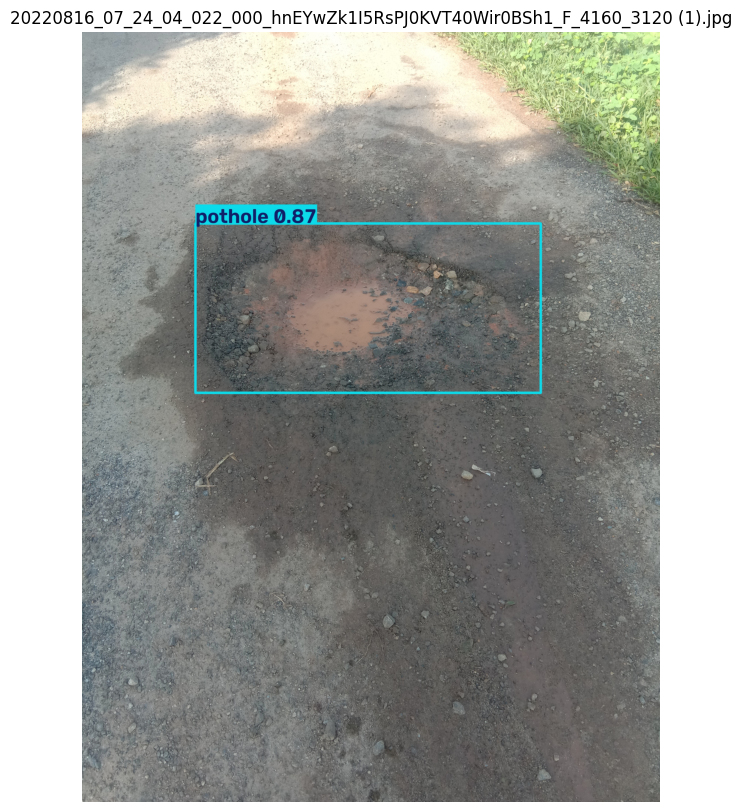

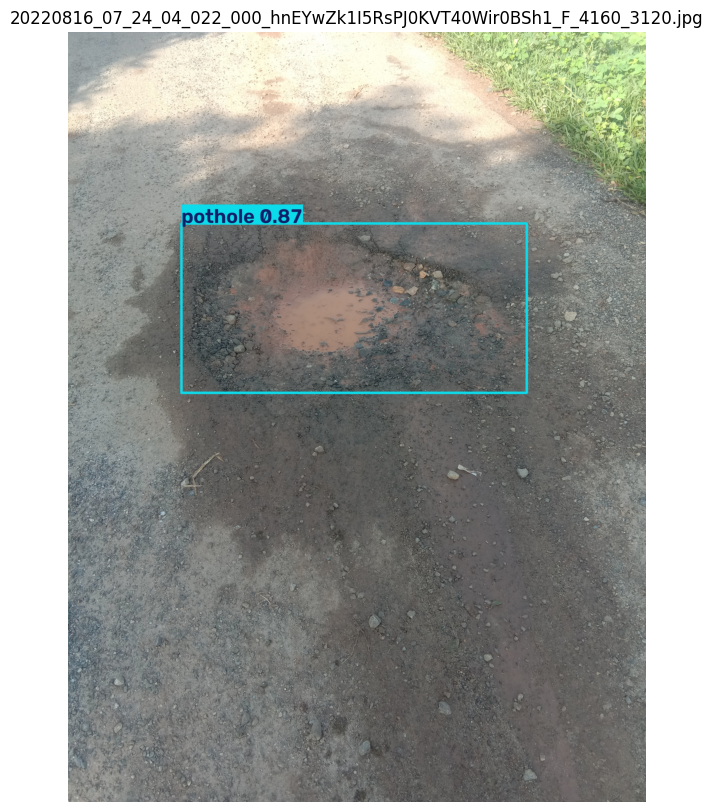

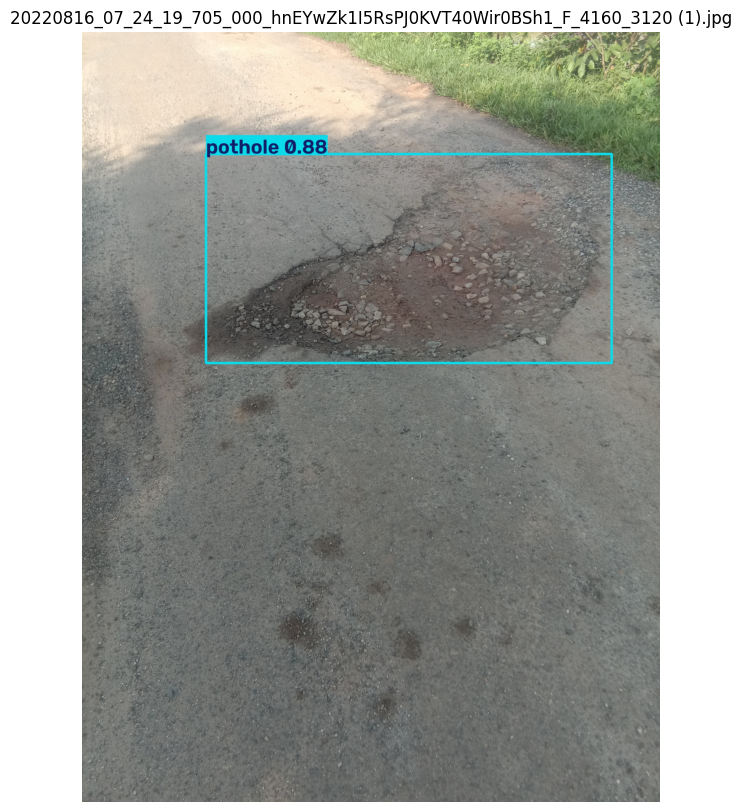

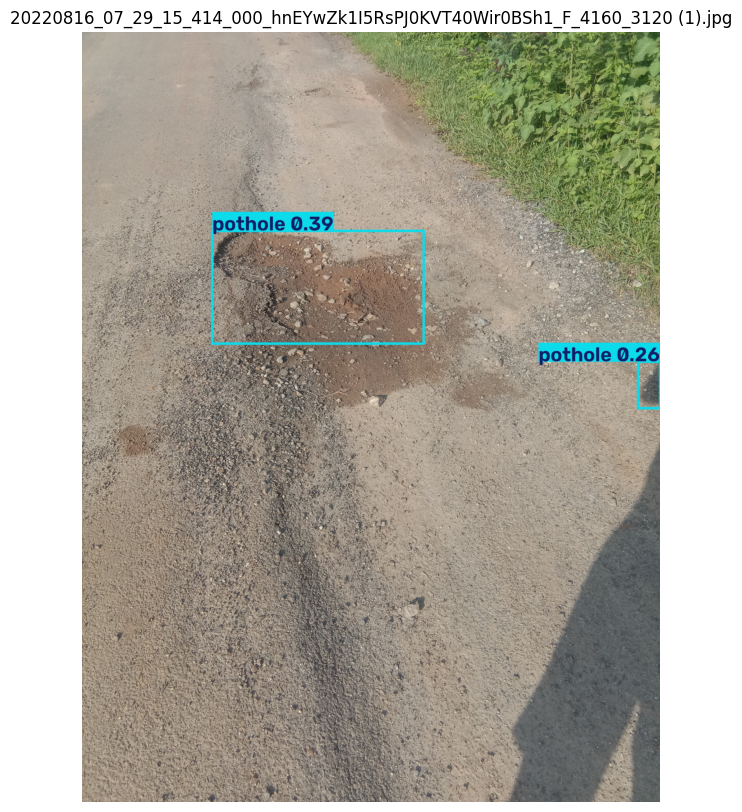

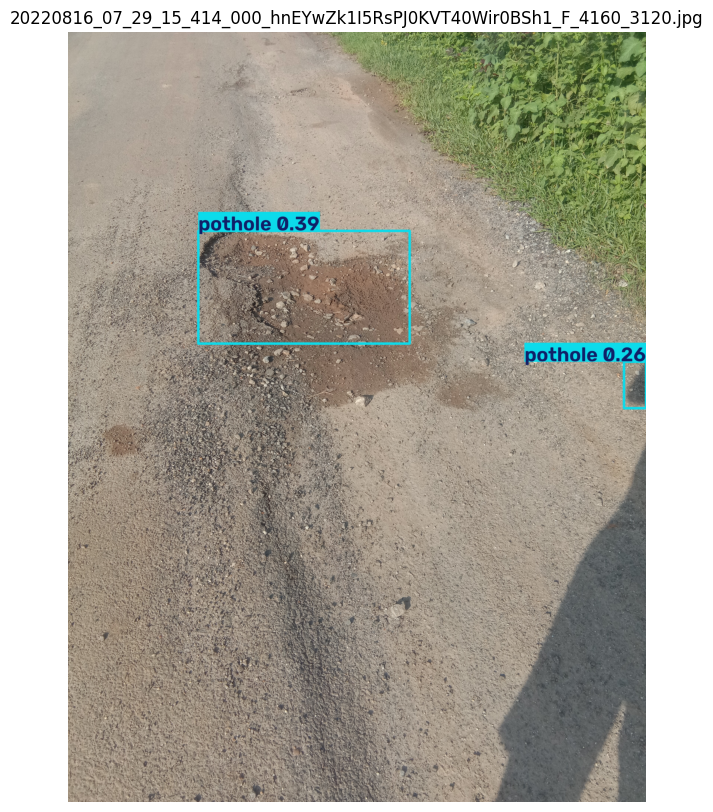

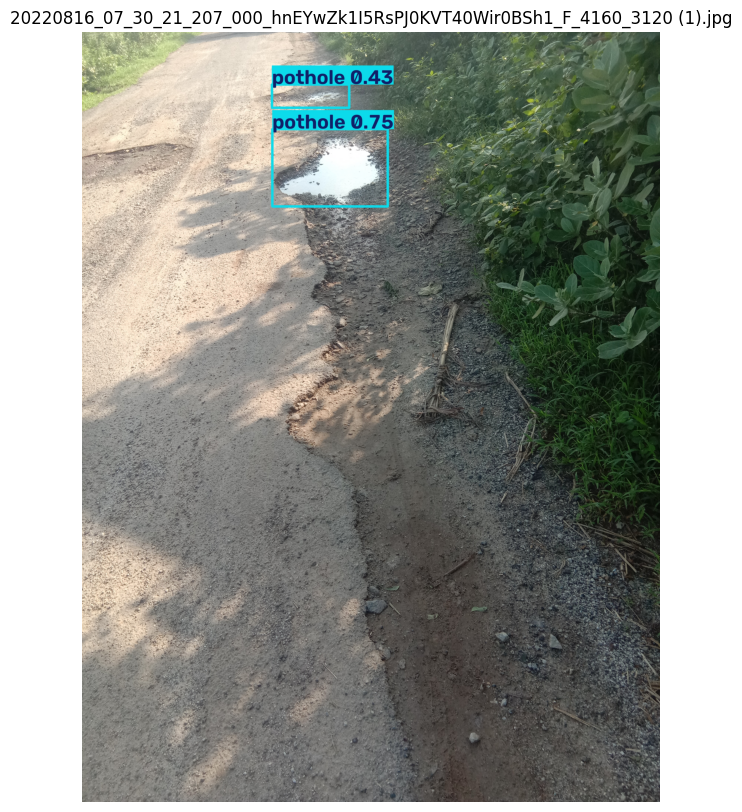

In [63]:
pred_dir = Path(TEST_PRED_DIR) / "test_predictions"

predicted_images = []
for ext in ["*.jpg", "*.jpeg", "*.png", "*.webp"]:
    predicted_images.extend(pred_dir.glob(ext))

print("Predicted images found:", len(predicted_images))

for image_path in predicted_images[:6]:
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 10))
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()


## Cell 23 — Test a New Image from Google Drive

Change `TEST_IMAGE` to the path of any road image you want to test.

In [64]:
TEST_IMAGE = "/content/drive/MyDrive/test_road.jpg"

if not os.path.exists(TEST_IMAGE):
    print("Image not found.")
    print("Change TEST_IMAGE to your actual image path.")
else:
    results = best_model.predict(
        source=TEST_IMAGE,
        conf=0.25,
        imgsz=IMG_SIZE,
        device=DEVICE,
        save=True
    )

    annotated = results[0].plot()

    plt.figure(figsize=(10, 12))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Road Crack / Pothole Detection")
    plt.show()


Image not found.
Change TEST_IMAGE to your actual image path.


## Cell 24 — Upload and Test an Image

This allows you to select a new image from your computer.

Saving 20220816_07_30_04_506_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120 (1).jpg to 20220816_07_30_04_506_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120 (1).jpg

image 1/1 /content/20220816_07_30_04_506_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120 (1).jpg: 640x480 1 pothole, 13.5ms
Speed: 2.9ms preprocess, 13.5ms inference, 93.7ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict-5


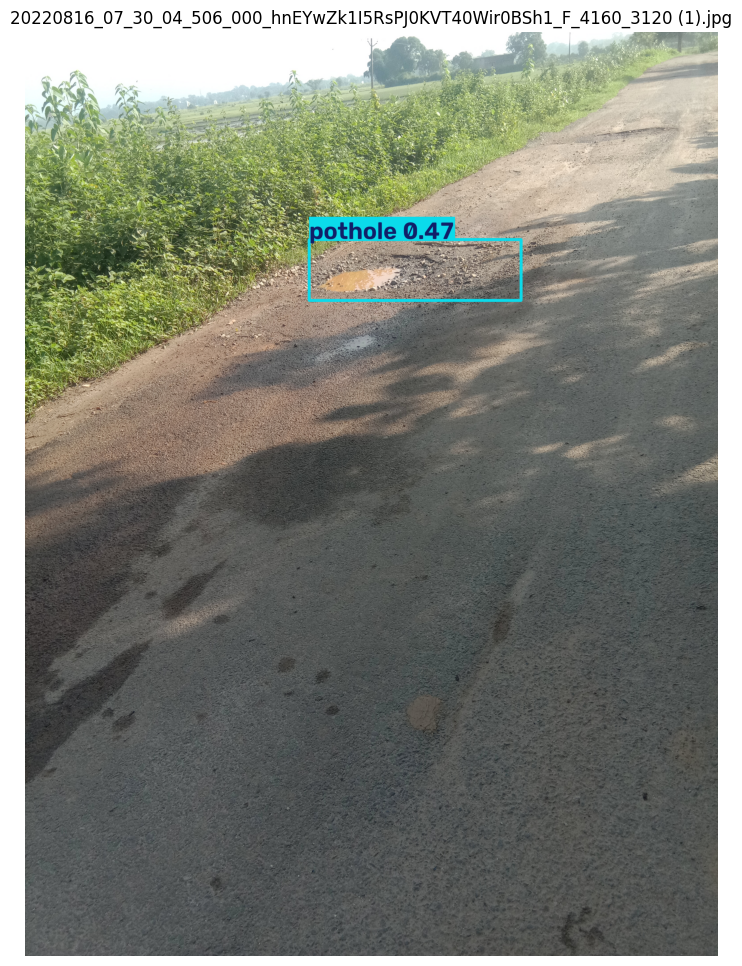

In [71]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    results = best_model.predict(
        source=filename,
        conf=0.25,
        imgsz=IMG_SIZE,
        device=DEVICE,
        save=True
    )

    annotated = results[0].plot()

    plt.figure(figsize=(10, 12))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(filename)
    plt.show()


## Cell 25 — Test a Road Video

Upload an MP4/AVI/MOV road video.

YOLO will process the video frame-by-frame and draw predicted bounding boxes.

In [70]:
uploaded_video = files.upload()

video_file = next(iter(uploaded_video.keys()), None)

if video_file:
    best_model.predict(
        source=video_file,
        conf=0.25,
        imgsz=IMG_SIZE,
        device=DEVICE,
        save=True,
        project=TEST_PRED_DIR,
        name="video_predictions",
        exist_ok=True
    )

    print("Video processing completed.")
    print(
        "Output folder:",
        os.path.join(TEST_PRED_DIR, "video_predictions")
    )


Saving pothole video-1.mp4 to pothole video-1.mp4

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/692) /content/pothole video-1.mp4: 384x640 7 potholes, 64.7ms
video 1/1 (frame 2/692) /content/pothole video-1.mp4: 384x640 6 potholes, 11.3ms
video 1/1 (frame 3/692) /content/pothole video-1.mp4: 384x640 6 potholes, 12.6ms
video 1/1 (frame 4/692) /content/pothole video-1.mp4: 384x640 8 potholes, 11.5ms
video 1/1 (frame 5/692) /content/pothole video-1.mp4: 384x640 8 potholes, 11.2ms
vide

## Cell 26 — Try Different Confidence Thresholds

A lower threshold gives more detections but may increase false positives.

A higher threshold gives fewer, more confident detections.

In [69]:
for confidence in [0.20, 0.25, 0.40, 0.50, 0.70]:
    predictions = best_model.predict(
        source=str(Path(YOLO_DATASET_DIR) / "test" / "images"),
        conf=confidence,
        imgsz=IMG_SIZE,
        device=DEVICE,
        verbose=False
    )

    total = sum(
        len(result.boxes) if result.boxes is not None else 0
        for result in predictions
    )

    print(f"Confidence {confidence:.2f}: {total} detections")


Confidence 0.20: 42 detections
Confidence 0.25: 36 detections
Confidence 0.40: 29 detections
Confidence 0.50: 25 detections
Confidence 0.70: 16 detections


## Cell 27 — Export the Trained Model to ONNX

In [ ]:
onnx_file = best_model.export(format="onnx")
print("ONNX model exported to:")
print(onnx_file)


# Final Project Explanation

## Bounding box

A bounding box is a rectangle showing **where the defect is located** in the image.

Your XML contains:

```xml
<xmin>1273</xmin>
<ymin>1071</ymin>
<xmax>1531</xmax>
<ymax>1239</ymax>
```

These four values describe the rectangle around one pothole.

## XML annotation

Your XML is a **Pascal VOC annotation**. It stores:

- image width and height
- object/class name
- bounding-box coordinates

## YOLO TXT annotation

YOLO uses one `.txt` file for each image.

The format is:

```text
class_id x_center y_center width height
```

For this project:

```text
0 = crack
1 = pothole
```

The notebook automatically converts your XML files into these TXT files.

## Why YOLO?

YOLO is a deep-learning object detection model. It predicts:

1. what the object is
2. where the object is
3. how confident the prediction is

## Evaluation

The notebook reports:

- **Precision**
- **Recall**
- **mAP50**
- **mAP50-95**

### Precision

How many predicted defects are actually correct.

### Recall

How many actual defects the model successfully detects.

### mAP50

Average precision when IoU threshold is 0.50.

### mAP50-95

A stricter metric averaged over IoU thresholds from 0.50 to 0.95.

## Recommended project title

**Road Crack and Pothole Detection Using YOLO and Deep Learning**


## Cell 28 — Final Summary

In [38]:
print("=" * 70)
print("ROAD CRACK & POTHOLE DETECTION - PROJECT SUMMARY")
print("=" * 70)

print("\nDataset:")
print(" Original:", SOURCE_DIR)
print(" YOLO:", YOLO_DATASET_DIR)

print("\nImages:")
print(" Total pairs:", len(paired_images))
print(" Train:", len(train_images))
print(" Valid:", len(valid_images))
print(" Test:", len(test_images))

print("\nClasses:")
for class_id, class_name in CLASS_NAMES.items():
    print(f" {class_id}: {class_name}")

print("\nObject counts:")
for class_name in CLASS_NAMES.values():
    print(f" {class_name}: {counts[class_name]}")

print("\nBest model:")
print(BEST_MODEL)

print("\nValidation metrics:")
print(f" Precision: {metrics.box.mp:.4f}")
print(f" Recall: {metrics.box.mr:.4f}")
print(f" mAP50: {metrics.box.map50:.4f}")
print(f" mAP50-95: {metrics.box.map:.4f}")

print("\nProject completed.")


ROAD CRACK & POTHOLE DETECTION - PROJECT SUMMARY

Dataset:
 Original: /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/Potholes
 YOLO: /content/drive/MyDrive/AI_Projects/Cracks_Patholes_Detection/road_defect_yolo_project/yolo_dataset

Images:
 Total pairs: 195
 Train: 156
 Valid: 19
 Test: 20

Classes:
 0: crack
 1: pothole

Object counts:
 crack: 0
 pothole: 514

Best model:
/content/drive/MyDrive/road_defect_project_runs/yolo11_road_defect/weights/best.pt

Validation metrics:
 Precision: 0.1801
 Recall: 0.0889
 mAP50: 0.0601
 mAP50-95: 0.0256

Project completed.
